# Học tăng cường (Reinforcement Learning)

Notebook này diễn giải bằng tiếng Việt các ý chính trong bài [Reinforcement Learning — GeeksforGeeks](https://www.geeksforgeeks.org/machine-learning/what-is-reinforcement-learning/) (cập nhật ngày 12/10/2026) và thực hành **Q-learning** với một mê cung. Phần lý thuyết được viết lại; ví dụ thực hành giữ bố cục bảy bước, lưới mê cung, tham số và thuật toán của bài nguồn.

**Mục tiêu:** hiểu cách agent học từ tương tác, đọc được công thức cập nhật Q và quan sát đường đi cùng phần thưởng sau khi huấn luyện.

**Thư viện cần có:** `numpy`, `matplotlib`. Chạy các cell theo thứ tự từ trên xuống; dữ liệu mê cung được tạo ngay trong notebook.

## 1. Học tăng cường là gì?

Học tăng cường (RL) là một nhánh học máy trong đó một **agent** thử các hành động trong **môi trường**, nhận phản hồi dưới dạng phần thưởng hoặc hình phạt, rồi điều chỉnh cách ra quyết định. Đích của agent là tối đa hóa **tổng phần thưởng tích lũy** qua thời gian, thay vì chỉ chọn hành động đem lại lợi ích ngay lúc này.

| Thuật ngữ | Ý nghĩa | Trong ví dụ mê cung |
|---|---|---|
| **Agent** | Chủ thể đưa ra quyết định và học từ kết quả | Robot tìm đường |
| **Environment** | Hệ thống mà agent tương tác | Mê cung có ô trống và vật cản |
| **State** | Tình huống hiện tại của agent | Tọa độ `(hàng, cột)` |
| **Action** | Lựa chọn agent có thể thực hiện | Đi trái, phải, lên hoặc xuống |
| **Reward** | Phản hồi sau một hành động | Thưởng khi tới đích, phạt khi đụng vật cản hoặc đi thêm bước |

Trong RL, cùng một hành động có thể mang giá trị khác nhau ở các trạng thái khác nhau. Agent cần học cách chọn hành động theo bối cảnh và theo hệ quả dài hạn của nó.

## 2. Các thành phần của một bài toán RL

| Thành phần | Vai trò | Minh họa với xe tự lái |
|---|---|---|
| **Policy (chính sách)** | Quy tắc ánh xạ trạng thái sang hành động; có thể là luật đơn giản hoặc mô hình phức tạp | Phát hiện người đi bộ và quyết định phanh |
| **Reward signal (tín hiệu thưởng)** | Diễn tả mục tiêu, giúp agent biết kết quả nào tốt hoặc xấu | Khuyến khích ít va chạm, đi đúng làn và rút ngắn thời gian |
| **Value function (hàm giá trị)** | Ước lượng lợi ích dài hạn của một trạng thái hoặc cặp trạng thái–hành động | Ưu tiên chạy an toàn thay vì một thao tác nhanh nhưng rủi ro |
| **Model (mô hình môi trường)** | Dự đoán trạng thái và phần thưởng có thể xảy ra sau hành động để hỗ trợ lập kế hoạch | Dự đoán chuyển động của các xe khác |

Không phải thuật toán RL nào cũng cần một mô hình môi trường. **Q-learning** ở phần thực hành học giá trị hành động trực tiếp từ trải nghiệm.

## 3. Agent học như thế nào?

Một vòng tương tác thường gồm: **quan sát trạng thái → chọn hành động theo policy → môi trường chuyển trạng thái và trả thưởng → cập nhật hiểu biết của agent**. Vòng này lặp lại qua nhiều bước và nhiều lần thử (*episode*).

Agent phải cân bằng hai lựa chọn:

- **Exploration (khám phá):** thử hành động mới để thu thập thông tin.
- **Exploitation (khai thác):** dùng hành động hiện được ước lượng là tốt nhất.

Quá trình này thường được mô tả bằng **Markov Decision Process (MDP)**. Trong giả định Markov, phân phối trạng thái kế tiếp được xác định bởi trạng thái và hành động hiện tại; không cần toàn bộ lịch sử trước đó. Mục tiêu vẫn là tối đa hóa phần thưởng tích lũy, có thể có hệ số chiết khấu để phân biệt phần thưởng gần và xa.

## 4. Ví dụ thực hành: Q-learning tìm đường trong mê cung

Mỗi vị trí hợp lệ là một trạng thái. Agent có bốn hành động di chuyển. Ô `0` là lối đi, ô `1` là vật cản. Đụng vật cản kết thúc lượt thử với phần thưởng `-10`; tới đích kết thúc lượt thử với phần thưởng `+50`; mỗi bước hợp lệ khác nhận `-1`. Cách đặt thưởng này khuyến khích đi tới đích bằng đường ngắn.

### Bước 1 — Nạp thư viện, tạo mê cung và xác định điểm đầu/cuối

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

maze = np.array([
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 0, 0],
])

start = (0, 0)
goal = (9, 9)

### Bước 2 — Đặt tham số và khởi tạo bảng Q

- `num_episodes = 5000`: số lượt agent thử đi qua mê cung.
- `alpha = 0.1`: tốc độ điều chỉnh ước lượng Q sau một quan sát mới.
- `gamma = 0.9`: mức coi trọng phần thưởng trong tương lai.
- `epsilon = 0.5`: xác suất thử hành động ngẫu nhiên lúc bắt đầu.
- `Q[hàng, cột, hành_động]`: giá trị ước lượng của hành động tại một ô; ban đầu mọi giá trị bằng `0`.

Thứ tự hành động là **trái, phải, lên, xuống**. Trong quá trình học, `epsilon` giảm dần nhưng không thấp hơn `0.01`.

In [2]:
num_episodes = 5000
alpha = 0.1
gamma = 0.9
epsilon = 0.5

reward_fire = -10
reward_goal = 50
reward_step = -1

actions = [(0, -1), (0, 1), (-1, 0), (1, 0)]
Q = np.zeros(maze.shape + (len(actions),))

### Bước 3 — Kiểm tra ô hợp lệ và chọn hành động

Một ô hợp lệ phải nằm trong ranh giới mê cung và không phải vật cản. Chiến lược **ε-greedy** chọn hành động ngẫu nhiên với xác suất `epsilon`; ở các lần còn lại, agent chọn hành động có giá trị Q cao nhất tại trạng thái hiện tại.

In [3]:
def is_valid(pos):
    row, col = pos
    return (
        0 <= row < maze.shape[0]
        and 0 <= col < maze.shape[1]
        and maze[row, col] == 0
    )


def choose_action(state):
    if np.random.random() < epsilon:
        return np.random.randint(len(actions))
    return np.argmax(Q[state])

### Bước 4 — Huấn luyện bằng Q-learning

Sau khi thực hiện hành động $a$ tại trạng thái $s$, agent nhận phần thưởng $r$ và quan sát trạng thái tiếp theo $s'$. Bảng Q được cập nhật theo:

$$
Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma\max_{a'}Q(s',a') - Q(s,a)\right].
$$

Ở đây, $\alpha$ là tốc độ học và $\gamma$ là hệ số chiết khấu. Nếu lượt thử kết thúc vì đụng vật cản hoặc tới đích, giá trị tương lai được đặt bằng `0`. Mỗi episode ghi lại tổng phần thưởng để xem quá trình học.

In [4]:
rewards_all_episodes = []

for episode in range(num_episodes):
    state = start
    total_rewards = 0
    done = False

    while not done:
        action_index = choose_action(state)
        move = actions[action_index]
        next_state = (state[0] + move[0], state[1] + move[1])

        if not is_valid(next_state):
            reward = reward_fire
            done = True
            next_max = 0
        elif next_state == goal:
            reward = reward_goal
            done = True
            next_max = 0
        else:
            reward = reward_step
            next_max = np.max(Q[next_state])

        old_value = Q[state][action_index]
        Q[state][action_index] = old_value + alpha * (
            reward + gamma * next_max - old_value
        )

        if is_valid(next_state):
            state = next_state
        total_rewards += reward

    epsilon = max(0.01, epsilon * 0.995)
    rewards_all_episodes.append(total_rewards)

### Bước 5 — Trích xuất đường đi theo bảng Q

Từ điểm xuất phát, ta chọn hành động có Q lớn nhất trong số các bước dẫn tới ô hợp lệ và chưa thăm. Tập `visited` ngăn vòng lặp; `max_steps` là giới hạn an toàn khi dựng đường. Do huấn luyện có yếu tố ngẫu nhiên, đường thu được có thể khác nhau giữa các lần chạy.

In [5]:
def get_optimal_path(Q, start, goal, actions, maze, max_steps=200):
    path = [start]
    state = start
    visited = set()

    for _ in range(max_steps):
        if state == goal:
            break
        visited.add(state)
        best_action = None
        best_value = -float('inf')

        for index, move in enumerate(actions):
            next_state = (state[0] + move[0], state[1] + move[1])
            if (
                0 <= next_state[0] < maze.shape[0]
                and 0 <= next_state[1] < maze.shape[1]
                and maze[next_state] == 0
                and next_state not in visited
                and Q[state][index] > best_value
            ):
                best_value = Q[state][index]
                best_action = index

        if best_action is None:
            break
        move = actions[best_action]
        state = (state[0] + move[0], state[1] + move[1])
        path.append(state)

    return path


optimal_path = get_optimal_path(Q, start, goal, actions, maze)
print(f"Số ô trên đường đi: {len(optimal_path)}")
print(f"Đã tới đích: {optimal_path[-1] == goal}")

Số ô trên đường đi: 25
Đã tới đích: True


### Bước 6 — Vẽ mê cung và đường đi đã học

Hình sau đánh dấu điểm bắt đầu, đích đến và các ô mà agent chọn theo bảng Q sau huấn luyện. Các vùng màu đậm là vật cản.

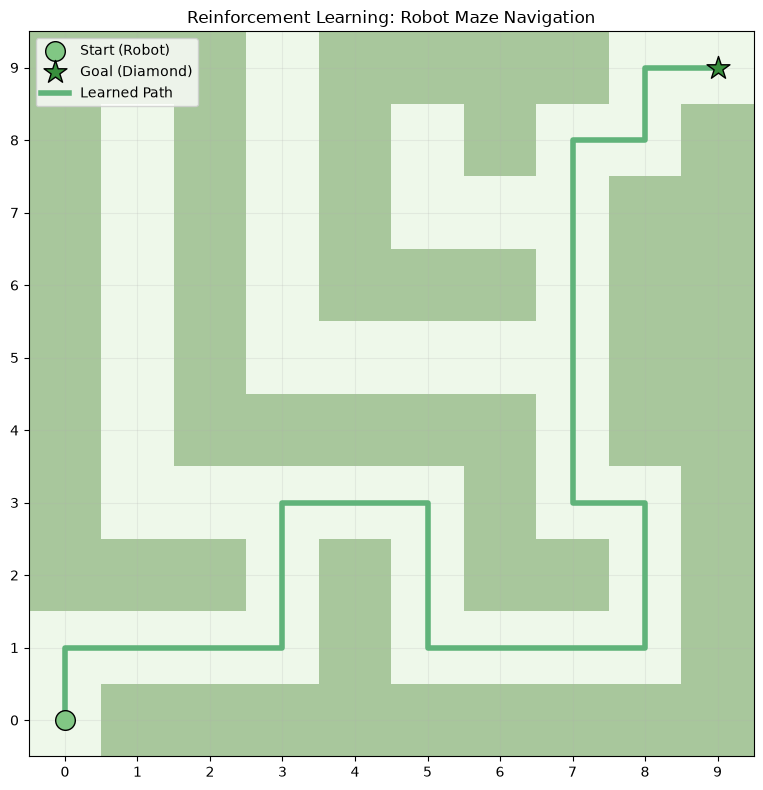

In [6]:
def plot_maze_with_path(path):
    cmap = ListedColormap(['#eef8ea', '#a8c79c'])
    plt.figure(figsize=(8, 8))
    plt.imshow(maze, cmap=cmap)
    plt.scatter(start[1], start[0], marker='o', color='#81c784',
                edgecolors='black', s=200, label='Start (Robot)', zorder=5)
    plt.scatter(goal[1], goal[0], marker='*', color='#388e3c',
                edgecolors='black', s=300, label='Goal (Diamond)', zorder=5)
    rows, cols = zip(*path)
    plt.plot(cols, rows, color='#60b37a', linewidth=4,
             label='Learned Path', zorder=4)
    plt.title('Reinforcement Learning: Robot Maze Navigation')
    plt.gca().invert_yaxis()
    plt.xticks(range(maze.shape[1]))
    plt.yticks(range(maze.shape[0]))
    plt.grid(True, alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_maze_with_path(optimal_path)

### Bước 7 — Vẽ tổng phần thưởng qua các episode

Đường biểu diễn cho thấy kết quả từng lượt thử. Dao động vẫn có thể xuất hiện vì agent tiếp tục khám phá; xu hướng phần thưởng giúp quan sát quá trình cải thiện.

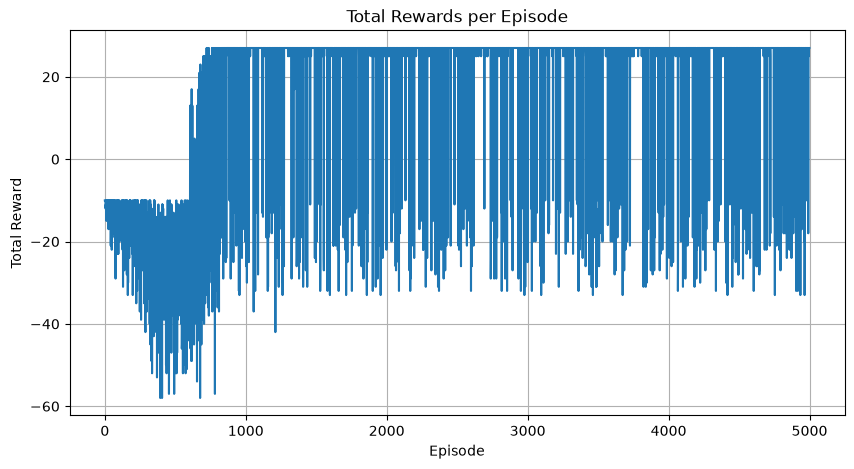

In [7]:
def plot_rewards(rewards):
    plt.figure(figsize=(10, 5))
    plt.plot(rewards)
    plt.title('Total Rewards per Episode')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.grid(True)
    plt.show()


plot_rewards(rewards_all_episodes)

## 5. Tăng cường dương và tăng cường âm

- **Tăng cường dương:** một kết quả dễ chịu xuất hiện sau hành vi và làm hành vi đó có xu hướng lặp lại nhiều hơn. Theo bài nguồn, cách này có thể nâng hiệu quả và duy trì thay đổi, nhưng dùng quá mức có thể làm việc học kém hiệu quả.
- **Tăng cường âm:** một điều kiện khó chịu được loại bỏ hoặc tránh được sau hành vi, từ đó hành vi có xu hướng tăng lên. Cách này giúp duy trì mức thực hiện tối thiểu, nhưng đôi khi chỉ thúc đẩy agent làm đủ để tránh điều kiện bất lợi.

**Lưu ý thuật ngữ:** tăng cường âm nói về việc *loại bỏ điều kiện bất lợi*, không đồng nghĩa với việc cộng một “phần thưởng âm” để phạt. Trong ví dụ mê cung, `reward_fire = -10` là một hình phạt trong hàm thưởng.

## 6. Học tăng cường online và offline

Trong **online RL**, agent tự tương tác với môi trường trong lúc học, liên tục thu thập trạng thái, hành động và phần thưởng mới. Trong **offline RL** (còn gọi là *batch RL*), agent chỉ học từ bộ dữ liệu tương tác đã thu thập trước đó, chẳng hạn nhật ký lịch sử hoặc thao tác của người khác; quá trình huấn luyện không yêu cầu tương tác mới với môi trường.

| Tiêu chí | Online RL | Offline RL |
|---|---|---|
| Nguồn dữ liệu | Tương tác trực tiếp, dữ liệu mới theo thời gian | Tập dữ liệu cố định đã ghi lại |
| Khả năng thích ứng | Có thể thích ứng liên tục | Bị giới hạn bởi phạm vi dữ liệu có sẵn |
| Khi phù hợp | Có thể truy cập môi trường hoặc mô phỏng | Thử nghiệm thật tốn kém hoặc có rủi ro |
| Thách thức | Tốn tài nguyên; khám phá có thể thiếu an toàn | Lệch phân phối; khó ước lượng kết quả của hành động chưa có trong dữ liệu |

Ví dụ Q-learning trong notebook thuộc **online RL** vì agent tự thử di chuyển và nhận phản hồi trong lúc học.

## 7. Ứng dụng, ưu điểm và hạn chế

**Ứng dụng được bài viết nêu:**

- **Robot:** học và tối ưu chuyển động trong các môi trường có cấu trúc, như dây chuyền sản xuất.
- **Trò chơi:** tìm chiến lược cho cờ vua, cờ vây hoặc trò chơi điện tử.
- **Điều khiển công nghiệp:** điều chỉnh hoạt động theo thời gian thực để tối ưu quy trình.
- **Hệ thống học tập cá nhân hóa:** chọn nội dung theo cách học của từng người.

**Ưu điểm:** RL xử lý các quyết định nối tiếp; có thể thích ứng thông qua tương tác; không cần nhãn đáp án như học có giám sát; đôi khi tìm ra chiến lược mới; và có thể hoạt động trong môi trường bất định.

**Hạn chế:** việc học thường cần nhiều dữ liệu và tính toán; thiết kế hàm thưởng sai có thể dẫn tới hành vi ngoài ý muốn; với bài toán đơn giản, phương pháp truyền thống có thể hiệu quả hơn; hành vi học được có thể khó gỡ lỗi hoặc giải thích; và cân bằng khám phá–khai thác không dễ.

**Nguồn tham khảo:** [GeeksforGeeks — Reinforcement Learning](https://www.geeksforgeeks.org/machine-learning/what-is-reinforcement-learning/).